# 03 Hypothesis testing 
**Goal:** turn the patterns we saw in the EDA into evidence. For each hypothesis (H1–H6) we ask: *how strong is the association, and could it be chance?*

**How to read the results**
- **p-value** answers "could this be chance?". With 26,707 people almost everything is significant, so p alone is not informative.
- **Effect size** answers "does it matter?". We use **Cramér's V** (0 = none, 1 = perfect; < 0.1 weak, 0.1–0.3 moderate, > 0.3 strong), **differences in percentage points (pp)** with a 95 % confidence interval, and an **odds ratio** for the two vaccines.
- These are **associations**, not causes.

In [14]:
import sys
from pathlib import Path

In [13]:
root = Path.cwd().resolve()
while not (root / "src" / "hypothesis.py").exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root))

In [12]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from src.hypothesis import (TARGETS, association_table, cramers_v, rate_difference,
                            odds_ratio, spearman)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)

In [15]:
X = pd.read_csv(root / "data" / "training_set_features.csv")
y = pd.read_csv(root / "data" / "training_set_labels.csv")
df = X.merge(y, on="respondent_id", validate="one_to_one")     # raw data; missing answers = own group
features = [c for c in X.columns if c != "respondent_id"]
print(df.shape)

(26707, 38)


## 1. Which features matter most? (all hypotheses at once)
We compute Cramér's V for **every** feature against **each** vaccine. This ranking shows where the signal is before we test individual hypotheses.

In [2]:
assoc = association_table(df, features)
top = assoc[["V h1n1", "V seasonal"]]
display(top.sort_values("V h1n1", ascending=False).head(10))
display(top.sort_values("V seasonal", ascending=False).head(10))

,V h1n1,V seasonal
feature,,
doctor_recc_h1n1,0.396,0.202
opinion_h1n1_risk,0.327,0.221
opinion_h1n1_vacc_effective,0.302,0.215
opinion_seas_risk,0.257,0.389
health_insurance,0.246,0.167
doctor_recc_seasonal,0.225,0.361
opinion_seas_vacc_effective,0.195,0.397
employment_industry,0.184,0.204
employment_occupation,0.183,0.193


,V h1n1,V seasonal
feature,,
opinion_seas_vacc_effective,0.195,0.397
opinion_seas_risk,0.257,0.389
doctor_recc_seasonal,0.225,0.361
age_group,0.051,0.285
opinion_h1n1_risk,0.327,0.221
opinion_h1n1_vacc_effective,0.302,0.215
employment_industry,0.184,0.204
doctor_recc_h1n1,0.396,0.202
employment_occupation,0.183,0.193


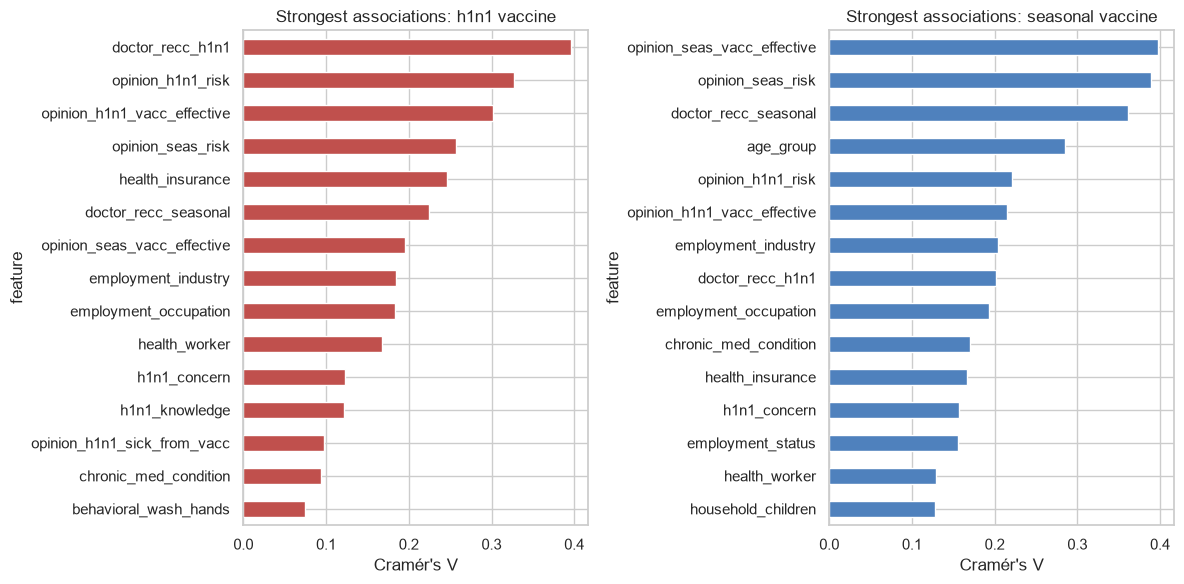

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharex=True)
for ax, col, color in zip(axes, ["V h1n1", "V seasonal"], ["#c0504d", "#4f81bd"]):
    top[col].sort_values().tail(15).plot.barh(ax=ax, color=color)
    ax.set_title(f"Strongest associations: {col[2:]} vaccine"); ax.set_xlabel("Cramér's V")
plt.tight_layout(); plt.show()

**Reading (check against your output):**
- For **H1N1** the top features are the doctor's recommendation (V ≈ 0.40), perceived risk (0.33) and perceived vaccine effectiveness (0.30).
- For **seasonal flu** the top features are perceived effectiveness (0.40), perceived risk (0.39), doctor's recommendation (0.36) and age (0.29).
- Demographics such as sex, race, education and income are all **weak** (V < 0.11).

## 2. H1 – Beliefs influence vaccination

In [4]:
pairs = [("opinion_h1n1_vacc_effective", "h1n1_vaccine"), ("opinion_h1n1_risk", "h1n1_vaccine"),
         ("opinion_h1n1_sick_from_vacc", "h1n1_vaccine"), ("h1n1_concern", "h1n1_vaccine"),
         ("opinion_seas_vacc_effective", "seasonal_vaccine"), ("opinion_seas_risk", "seasonal_vaccine"),
         ("opinion_seas_sick_from_vacc", "seasonal_vaccine")]
pd.DataFrame([spearman(df, c, t) for c, t in pairs])

,feature,target,n,spearman rho,p
0,opinion_h1n1_vacc_effective,h1n1,26316,0.292,0.000000e+00
1,opinion_h1n1_risk,h1n1,26319,0.306,0.000000e+00
2,opinion_h1n1_sick_from_vacc,h1n1,26312,0.059,9.389346e-22
3,h1n1_concern,h1n1,26615,0.123,9.619818e-90
4,opinion_seas_vacc_effective,seasonal,26245,0.398,0.000000e+00
5,opinion_seas_risk,seasonal,26193,0.389,0.000000e+00
6,opinion_seas_sick_from_vacc,seasonal,26170,-0.075,2.466676e-34


**Verdict H1 + H4 (risk perception): supported.** Perceived effectiveness and perceived risk have moderate-to-strong rank correlations (ρ ≈ 0.29–0.40). Concern and knowledge are weaker (ρ ≈ 0.12). The "worry about getting sick from the vaccine" scale is almost flat (ρ between −0.08 and +0.06), so it matters little by itself.

⚠️ *Reverse causality:* people who have been vaccinated may later report higher trust in the vaccine, so these opinions may partly be a **result** of vaccination.

## 3. H2 – Demographics are key drivers

In [5]:
demo = ["age_group", "sex", "race", "education", "income_poverty", "employment_status",
        "marital_status", "rent_or_own", "census_msa", "hhs_geo_region", "household_adults", "household_children"]
assoc.loc[demo, ["V h1n1", "V seasonal", "p h1n1", "p seasonal"]].sort_values("V seasonal", ascending=False)

,V h1n1,V seasonal,p h1n1,p seasonal
feature,,,,
age_group,0.051,0.285,2.971603e-14,0.000000e+00
employment_status,0.034,0.156,7.656468e-07,9.205539e-140
household_children,0.017,0.128,1.217811e-01,2.822027e-93
rent_or_own,0.036,0.110,3.586457e-08,1.649862e-71
race,0.046,0.105,2.555777e-12,1.378102e-63
education,0.070,0.081,3.664435e-27,1.784114e-36
household_adults,0.036,0.081,4.218679e-07,7.059469e-37
sex,0.021,0.077,7.294573e-04,2.155286e-36
income_poverty,0.060,0.076,1.928282e-20,5.455880e-33


**Verdict H2: partly supported.** Only **age** stands out, and only for the seasonal vaccine (V ≈ 0.29; for H1N1 only 0.05). Everything else is weak (V ≤ 0.13): the largest is `employment_status` (V ≈ 0.16 for seasonal), which is mostly age in disguise (see 3b). Some results are "significant" but tiny (e.g. `sex` for H1N1: V ≈ 0.02), and `census_msa` shows no effect on H1N1 (p ≈ 0.94). This is exactly why we look at V and not only at p.

### 3b. Is the employment effect really about age?
People *not in the labor force* vaccinate most for seasonal flu, but 53 % of them are 65+ (against 7 % of the employed). Compare within age groups:

In [6]:
display(df.pivot_table(index="age_group", columns="employment_status",
                       values="seasonal_vaccine", aggfunc="mean").mul(100).round(1))
share65 = df.groupby("employment_status")["age_group"].apply(lambda s: (s == "65+ Years").mean() * 100).round(1)
display(share65.to_frame("% aged 65+"))

employment_status,Employed,Not in Labor Force,Unemployed
age_group,,,
18 - 34 Years,30.0,26.8,20.0
35 - 44 Years,37.6,37.4,24.1
45 - 54 Years,41.5,41.0,30.8
55 - 64 Years,52.5,52.0,38.6
65+ Years,61.3,68.9,58.1


,% aged 65+
employment_status,
Employed,7.5
Not in Labor Force,53.3
Unemployed,7.2


In [7]:
overall, _ = cramers_v(df, "employment_status", "seasonal_vaccine")
within = []
for age, g in df.groupby("age_group"):
    v, _ = cramers_v(g, "employment_status", "seasonal_vaccine")
    within.append(v)
print(f"V(employment, seasonal) overall: {overall:.3f}")
print(f"V(employment, seasonal) inside each age group: {np.round(within, 3)} (mean {np.mean(within):.3f})")

V(employment, seasonal) overall: 0.156
V(employment, seasonal) inside each age group: [0.067 0.074 0.07  0.075 0.064] (mean 0.070)


**Reading:** the employment effect drops from V ≈ 0.16 to about 0.07 once we compare people of the same age, so about half of it is **age in disguise** (retired people). What remains: *unemployed* people vaccinate less than employed people of the same age (e.g. 20 % vs 30 % at ages 18–34). This is a **confounding** example worth showing in the presentation.

## 4. H3 – Preventive behaviours correlate with uptake

In [8]:
beh = [c for c in df.columns if c.startswith("behavioral_")]
df["behavior_score"] = df[beh].sum(axis=1)            # temporary column, number of behaviours (0-7)
res = pd.DataFrame([spearman(df, "behavior_score", t) for t in TARGETS])
display(res)
display(assoc.loc[beh, ["V h1n1", "V seasonal"]].sort_values("V h1n1", ascending=False))

,feature,target,n,spearman rho,p
0,behavior_score,h1n1,26707,0.076,3.523720e-35
1,behavior_score,seasonal,26707,0.123,9.267647e-91


,V h1n1,V seasonal
feature,,
behavioral_wash_hands,0.075,0.112
behavioral_touch_face,0.073,0.120
behavioral_face_mask,0.071,0.050
behavioral_avoidance,0.049,0.076
behavioral_antiviral_meds,0.047,0.023
behavioral_outside_home,0.024,0.053
behavioral_large_gatherings,0.019,0.064


**Verdict H3: weak.** The behaviour score has ρ ≈ 0.08 (H1N1) and 0.12 (seasonal), and no single behaviour exceeds V ≈ 0.08. People who take precautions vaccinate slightly more, but behaviours are poor predictors on their own.

## 5. H5 – The two vaccines are correlated

In [9]:
display(pd.crosstab(df["h1n1_vaccine"], df["seasonal_vaccine"], normalize="index").mul(100).round(1))
odds_ratio(df, "h1n1_vaccine", "seasonal_vaccine")

seasonal_vaccine,0,1
h1n1_vaccine,,
0,63.2,36.8
1,17.2,82.8


{'odds ratio': np.float64(8.26), 'CI low': 7.67, 'CI high': 8.9, 'phi': 0.377}

**Verdict H5: strongly supported.** The odds of having the H1N1 vaccine are about **8 times higher** (95 % CI 7.7–8.9) for people who had the seasonal vaccine. φ ≈ 0.38.

## 6. H6 – Doctor recommendation and insurance are among the strongest predictors

In [10]:
rows = []
for col, t in [("doctor_recc_h1n1", "h1n1_vaccine"), ("doctor_recc_seasonal", "seasonal_vaccine"),
               ("health_insurance", "h1n1_vaccine"), ("health_insurance", "seasonal_vaccine"),
               ("health_worker", "h1n1_vaccine"), ("health_worker", "seasonal_vaccine"),
               ("chronic_med_condition", "h1n1_vaccine"), ("chronic_med_condition", "seasonal_vaccine")]:
    rows.append(rate_difference(df, col, t))
diff = pd.DataFrame(rows)
diff

,factor,target,rate if 1 (%),rate if 0 (%),difference (pp),CI low,CI high
0,doctor_recc_h1n1,h1n1,53.2,13.6,39.6,38.2,41.0
1,doctor_recc_seasonal,seasonal,73.8,34.6,39.2,38.0,40.4
2,health_insurance,h1n1,31.8,14.7,17.0,15.2,18.9
3,health_insurance,seasonal,53.8,22.9,30.9,28.7,33.0
4,health_worker,h1n1,40.9,18.9,22.1,20.2,23.9
5,health_worker,seasonal,64.7,44.6,20.2,18.3,22.0
6,chronic_med_condition,h1n1,27.5,18.9,8.7,7.5,9.8
7,chronic_med_condition,seasonal,60.4,41.5,18.8,17.5,20.2


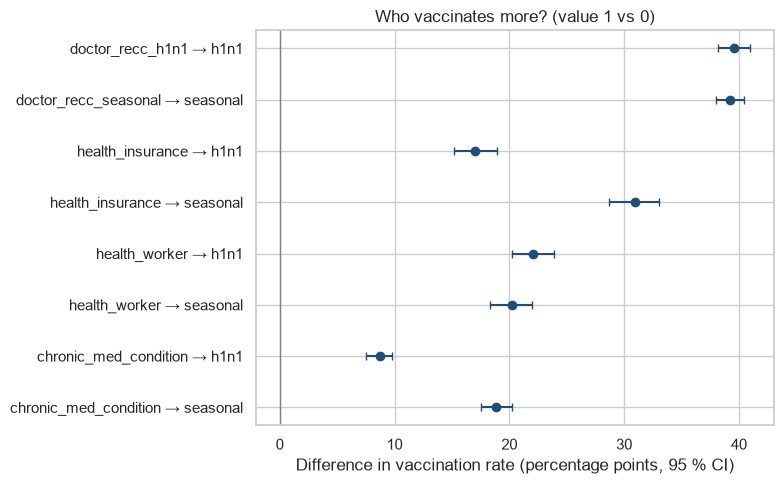

In [11]:
d = diff.assign(label=diff["factor"] + " → " + diff["target"]).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(d["difference (pp)"], range(len(d)),
            xerr=[d["difference (pp)"] - d["CI low"], d["CI high"] - d["difference (pp)"]],
            fmt="o", color="#1f4e79", capsize=3)
ax.set_yticks(range(len(d))); ax.set_yticklabels(d["label"]); ax.axvline(0, color="grey", lw=1)
ax.set_xlabel("Difference in vaccination rate (percentage points, 95 % CI)")
ax.set_title("Who vaccinates more? (value 1 vs 0)"); plt.tight_layout(); plt.show()

**Verdict H6: supported for the doctor's recommendation, partly for insurance.**
- A recommendation goes with a **+40 pp** higher uptake for both vaccines (95 % CI about ±1.4 pp for H1N1 and ±1.2 pp for seasonal), the strongest single factor for H1N1 and in the top 3 for seasonal flu.
- Insurance: +17 pp (H1N1) and +31 pp (seasonal), but it ranks only mid-table (V ≈ 0.25 for H1N1, 0.17 for seasonal). 46 % of the insurance answers are missing and those people behave differently (see notebook 02).
- Health workers (+22 pp for H1N1) and people with chronic conditions (+19 pp for seasonal) also vaccinate clearly more.

⚠️ A doctor tends to recommend the vaccine to people who are older, sicker or at higher risk, so part of this gap is not the recommendation itself.

## 7. Summary
| Hypothesis | Key evidence | Verdict |
|---|---|---|
| H1 Beliefs | Effectiveness ρ ≈ 0.29 (H1N1) / 0.40 (seasonal); "sick from vaccine" ≈ 0 | **Supported** (reverse causality possible) |
| H2 Demographics | Only age matters (V 0.29 for seasonal, 0.05 for H1N1); the rest V ≤ 0.16, and employment is mostly age | **Partly supported** |
| H3 Behaviours | Score ρ ≈ 0.08 / 0.12 | **Weak** |
| H4 Risk perception | Perceived risk ρ ≈ 0.31 / 0.39 | **Supported** |
| H5 Cross-vaccine | OR ≈ 8.3 (CI 7.7–8.9) | **Strongly supported** |
| H6 Doctor / insurance | Doctor +40 pp; insurance +17 / +31 pp | **Supported** (doctor), partly (insurance) |

**What this means for Sprint 2**
1. Features that must be in the model: doctor's recommendation, perceived risk, perceived effectiveness, age group, insurance, health worker, chronic condition.
2. Build a **risk-perception score** (risk + concern) and a **belief score** (effectiveness) for ticket 2.1.
3. Use the other vaccine's behaviour as context, but **do not** use one target as a feature for the other (leakage).
4. Demographics other than age add little; keep them anyway and let regularisation decide.
5. Compare models with ROC AUC, as the competition does.